# EDA — Novotel Siam Square Bangkok
### 2025 Voice of Guest (VOG) Reviews

One continuous notebook: **Part 1** cleans the raw data, **Part 2** runs univariate analysis, **Part 3** runs bivariate/multivariate analysis — all on the same `df` built once at the top. No re-downloading or re-uploading partway through. Run cells top to bottom (`Runtime > Restart session and run all` if you ever hit a `NameError` — it means cells were run out of order).

# Part 1 — Data Cleaning

## 1. Setup — imports + upload file
Select `2025_VOG_reviews.xlsx` when prompted. All libraries needed for cleaning and every chart later on are imported here up front.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from google.colab import files
uploaded = files.upload()


## 2. Load data

In [7]:
FILENAME = "2025 VOG reviews.xlsx"
raw = pd.read_excel(FILENAME, sheet_name="Reviews")

print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns")
raw.head()


Loaded 7,506 rows x 5 columns


,Published date,Source,Score,Title,Review Text
0,2025-12-31,TrustYou Survey,90.0,"Good location, short distance to BTS","Decent hotel, value for money and good service."
1,2025-12-31,TrustYou Survey,100.0,الغرفة قديمة بعض الشيء، وخيارات الإفطار الحلال...,NaN
2,2025-12-31,TrustYou Survey,100.0,NaN,NaN
3,2025-12-31,TrustYou Survey,100.0,บริการเป็นเลิศ ทำเลสะดวก ห้องพักสบาย,NaN
4,2025-12-31,TrustYou Survey,100.0,I would like to thank you to brother Abdullah ...,NaN


## 3. Initial inspection

In [8]:
print("--- dtypes ---")
print(raw.dtypes)
print("\n--- missing values ---")
print(raw.isna().sum())
print("\n--- summary ---")
print(raw.describe(include="all"))


--- dtypes ---
Published date     object
Source             object
Score             float64
Title              object
Review Text        object
dtype: object

--- missing values ---
Published date       0
Source               0
Score                0
Title             4091
Review Text       1892
dtype: int64

--- summary ---
       Published date      Source        Score        Title  \
count            7506        7506  7506.000000         3415   
unique            365          14          NaN         1998   
top        2025-08-07  google.com          NaN  Exceptional   
freq               48        3031          NaN          344   
mean              NaN         NaN    90.319345          NaN   
std               NaN         NaN    16.705951          NaN   
min               NaN         NaN    10.000000          NaN   
25%               NaN         NaN    80.000000          NaN   
50%               NaN         NaN   100.000000          NaN   
75%               NaN         NaN   100.00

## 4. Standardize column names
Work on a copy; rename to snake_case for easier referencing.

In [9]:
df = raw.copy()
df.columns = ["published_date", "source", "score", "title", "review_text"]
df.head()


,published_date,source,score,title,review_text
0,2025-12-31,TrustYou Survey,90.0,"Good location, short distance to BTS","Decent hotel, value for money and good service."
1,2025-12-31,TrustYou Survey,100.0,الغرفة قديمة بعض الشيء، وخيارات الإفطار الحلال...,NaN
2,2025-12-31,TrustYou Survey,100.0,NaN,NaN
3,2025-12-31,TrustYou Survey,100.0,บริการเป็นเลิศ ทำเลสะดวก ห้องพักสบาย,NaN
4,2025-12-31,TrustYou Survey,100.0,I would like to thank you to brother Abdullah ...,NaN


## 5. Duplicate check (informational only)
274 exact duplicate rows were found on prior inspection. These are not dropped automatically — many are short, common phrases ("Good service", "Excellent") that different guests could plausibly write independently. Inspect `df[df.duplicated(keep=False)]` manually if you want to confirm before deciding whether to dedupe.

In [10]:
n_exact_dupes = df.duplicated().sum()
print(f"Exact duplicate rows found: {n_exact_dupes}")


Exact duplicate rows found: 274


## 6. Clean string columns
Strip stray whitespace from text fields and standardize `source`.

In [11]:
for col in ["source", "title", "review_text"]:
    df[col] = df[col].where(df[col].isna(), df[col].astype(str).str.strip())

df["source"] = df["source"].str.strip()


## 7. Parse dates + derive time features

In [12]:
df["published_date"] = pd.to_datetime(df["published_date"], errors="coerce")

n_bad_dates = df["published_date"].isna().sum()
if n_bad_dates:
    print(f"WARNING: {n_bad_dates} rows had a date that failed to parse.")

df["year"] = df["published_date"].dt.year
df["month"] = df["published_date"].dt.month
df["month_name"] = df["published_date"].dt.month_name()
df["quarter"] = df["published_date"].dt.quarter
df["week"] = df["published_date"].dt.isocalendar().week
df["day_of_week"] = df["published_date"].dt.day_name()
df["is_weekend"] = df["published_date"].dt.dayofweek >= 5


## 8. Validate + bucket Score
Score is already normalized to a 0-100 scale. Bands:

| Range | Category |
|---|---|
| 90-100 | Excellent |
| 71-89 | Good |
| 60-70 | Fair |
| below 60 | Bad |

In [13]:
out_of_range = df[(df["score"] < 0) | (df["score"] > 100)]
if len(out_of_range):
    print(f"WARNING: {len(out_of_range)} rows have a score outside 0-100.")

df["score"] = pd.to_numeric(df["score"], errors="coerce")

score_order = ["Bad", "Fair", "Good", "Excellent"]
bins = [-np.inf, 59.999, 70, 89, np.inf]
df["score_category"] = pd.cut(df["score"], bins=bins, labels=score_order, right=True)
df["score_category"] = pd.Categorical(df["score_category"], categories=score_order, ordered=True)

print(df["score_category"].value_counts().reindex(score_order))


score_category
Bad           347
Fair          585
Good         1149
Excellent    5425
Name: count, dtype: int64


## 9. Missing-data flags
Not dropped — absence is meaningful. Many platforms allow a rating with no written feedback.

In [14]:
df["has_title"] = df["title"].notna()
df["has_review_text"] = df["review_text"].notna()

df["feedback_type"] = np.select(
    [
        df["has_title"] & df["has_review_text"],
        df["has_title"] & ~df["has_review_text"],
        ~df["has_title"] & df["has_review_text"],
    ],
    [
        "Title + Review Text",
        "Title Only",
        "Review Text Only",
    ],
    default="Rating Only",
)

print(df["feedback_type"].value_counts())


feedback_type
Review Text Only       3282
Title + Review Text    2332
Title Only             1083
Rating Only             809
Name: count, dtype: int64


## 10. Text feature engineering
Keep raw `title`/`review_text` untouched; build cleaned + derived columns.

In [15]:
df["review_text_clean"] = (
    df["review_text"]
    .fillna("")
    .str.replace(r"\s+", " ", regex=True)  # collapse newlines/extra whitespace
    .str.strip()
)

df["review_char_count"] = df["review_text_clean"].str.len()
df["review_word_count"] = df["review_text_clean"].str.split().str.len().fillna(0).astype(int)

# Restore true NaN where there was no review text (avoid treating "" as a review)
df.loc[~df["has_review_text"], ["review_char_count", "review_word_count"]] = np.nan


## 11. Set categorical dtypes
For efficient grouping and, importantly, so charts sort in a logical order (Mon→Sun, Jan→Dec) instead of alphabetically.

In [16]:
df["source"] = df["source"].astype("category")
df["feedback_type"] = df["feedback_type"].astype("category")

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=dow_order, ordered=True)

month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
df["month_name"] = pd.Categorical(df["month_name"], categories=month_order, ordered=True)


## 12. Final sanity check

In [17]:
print("--- Final shape ---")
print(df.shape)
print("\n--- Final dtypes ---")
print(df.dtypes)
print("\n--- Missing values (should only be title/review_text related) ---")
print(df.isna().sum())
print("\n--- Sample rows ---")
df.sample(5, random_state=1)


--- Final shape ---
(7506, 19)

--- Final dtypes ---
published_date       datetime64[ns]
source                     category
score                       float64
title                        object
review_text                  object
year                          int32
month                         int32
month_name                 category
quarter                       int32
week                         UInt32
day_of_week                category
is_weekend                     bool
score_category             category
has_title                      bool
has_review_text                bool
feedback_type              category
review_text_clean            object
review_char_count           float64
review_word_count           float64
dtype: object

--- Missing values (should only be title/review_text related) ---
published_date          0
source                  0
score                   0
title                4091
review_text          1892
year                    0
month                   0


,published_date,source,score,title,review_text,year,month,month_name,quarter,week,day_of_week,is_weekend,score_category,has_title,has_review_text,feedback_type,review_text_clean,review_char_count,review_word_count
2165,2025-09-18,google.com,100.0,NaN,Good service and safety hotel Sai,2025,9,September,3,38,Thursday,False,Excellent,False,True,Review Text Only,Good service and safety hotel Sai,33.0,6.0
4285,2025-06-16,trip.com,74.0,NaN,房間電話壞,2025,6,June,2,25,Monday,False,Good,False,True,Review Text Only,房間電話壞,5.0,1.0
2385,2025-09-08,google.com,100.0,NaN,We're repeat guests at Novotel Bangkok on Siam...,2025,9,September,3,37,Monday,False,Excellent,False,True,Review Text Only,We're repeat guests at Novotel Bangkok on Siam...,225.0,40.0
4656,2025-05-26,TrustYou Survey,80.0,Good stay,Staff are polite and helpful,2025,5,May,2,22,Monday,False,Good,True,True,Title + Review Text,Staff are polite and helpful,28.0,5.0
5832,2025-03-26,TrustYou Survey,50.0,Visit was So-So,"Initially, the room assigned to me on the 16th...",2025,3,March,1,13,Wednesday,False,Bad,True,True,Title + Review Text,"Initially, the room assigned to me on the 16th...",514.0,95.0


# Part 2 — Univariate Analysis

Continues directly from `df` above. Each variable is examined on its own before looking at relationships between variables in Part 3.

## 14. Plot style setup
Consistent look across all charts, plus a small helper to label bars with counts and percentages so every chart is self-explanatory.

In [18]:
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

PALETTE = "crest"
N = len(df)

def annotate_bars(ax, horizontal=False):
    """Add count + percentage labels to each bar in a bar chart."""
    for p in ax.patches:
        if horizontal:
            val = p.get_width()
            x, y = val, p.get_y() + p.get_height() / 2
            ha, va = "left", "center"
        else:
            val = p.get_height()
            x, y = p.get_x() + p.get_width() / 2, val
            ha, va = "center", "bottom"
        if val > 0:
            ax.annotate(f"{int(val):,}\n({val/N:.1%})", (x, y), ha=ha, va=va, fontsize=8.5)


## 15. Score distribution (discrete values)
Score isn't truly continuous here — only ~29 distinct values appear after normalization, and **100 alone accounts for roughly 62% of all reviews**. A discrete bar chart shows this much more honestly than a binned histogram would.

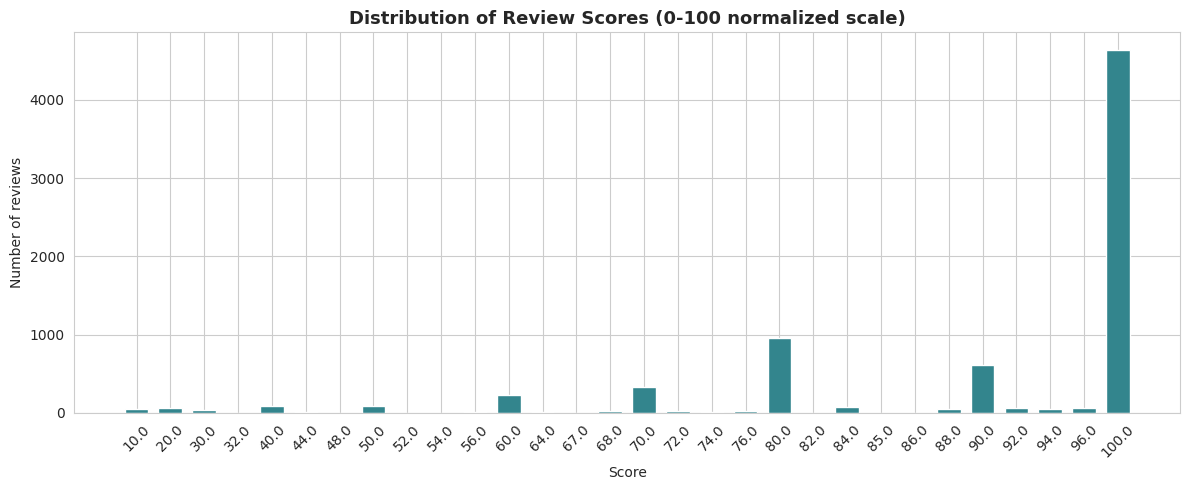

In [19]:
score_counts = df["score"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(score_counts.index.astype(str), score_counts.values, width=0.7,
       color=sns.color_palette(PALETTE, 1)[0])
ax.set_title("Distribution of Review Scores (0-100 normalized scale)")
ax.set_xlabel("Score")
ax.set_ylabel("Number of reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 16. Score category distribution

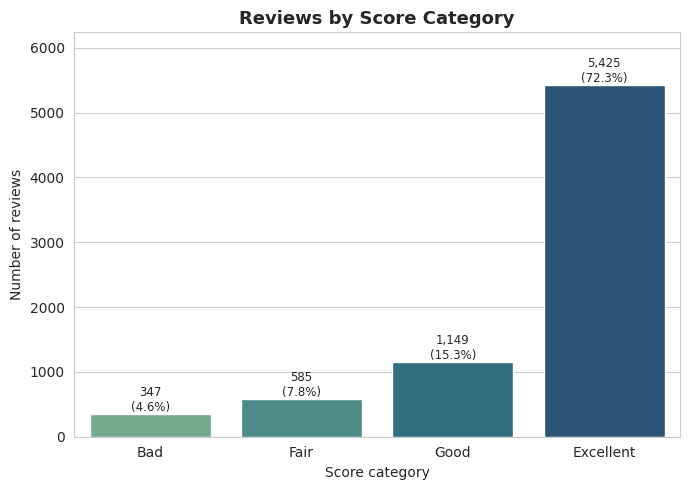

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
order_counts = df["score_category"].value_counts().reindex(score_order)
sns.barplot(x=order_counts.index, y=order_counts.values, palette=PALETTE, ax=ax,
            hue=order_counts.index, legend=False)
annotate_bars(ax)
ax.set_title("Reviews by Score Category")
ax.set_xlabel("Score category")
ax.set_ylabel("Number of reviews")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


## 17. Score spread (boxplot)
A quick check on spread and outliers beyond the discrete-value view above.

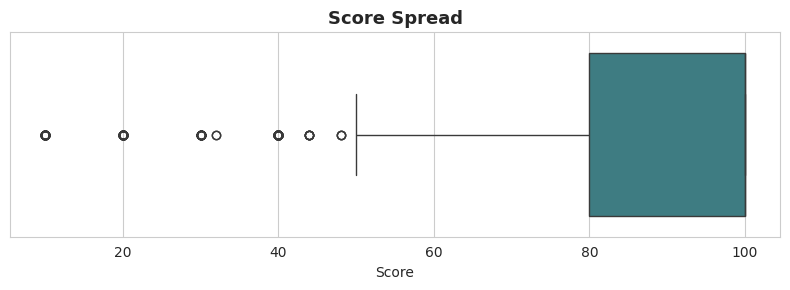

count    7506.000000
mean       90.319345
std        16.705951
min        10.000000
25%        80.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: score, dtype: float64


In [21]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=df["score"], color=sns.color_palette(PALETTE, 1)[0], ax=ax)
ax.set_title("Score Spread")
ax.set_xlabel("Score")
plt.tight_layout()
plt.show()

print(df["score"].describe())


## 18. Review source distribution
14 platforms feed into this dataset, but volume is extremely uneven — Google alone accounts for about 40% of reviews, while several sources have only 1-3. A horizontal bar chart handles the long source names and wide range better than a vertical one.

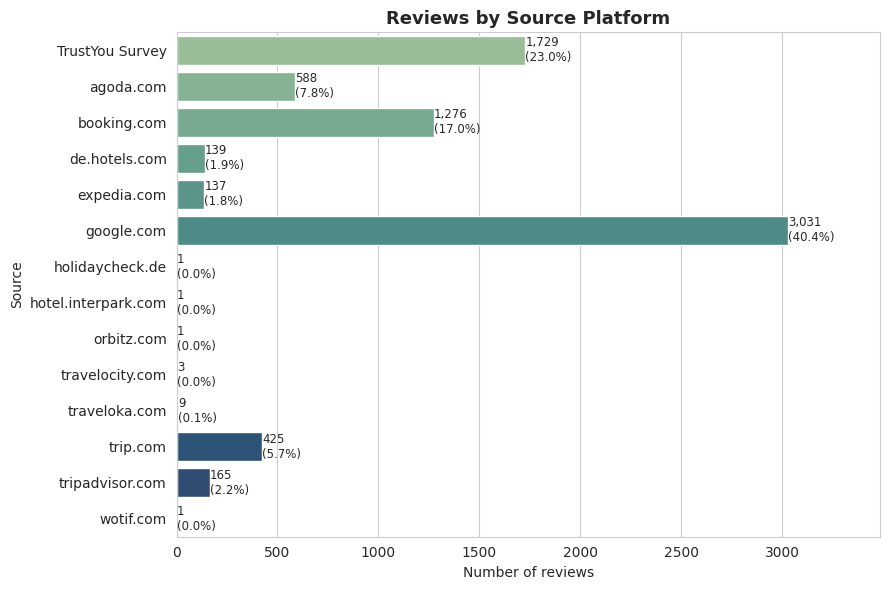

In [22]:
source_counts = df["source"].value_counts()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=source_counts.values, y=source_counts.index, palette=PALETTE, ax=ax,
            hue=source_counts.index, legend=False)
annotate_bars(ax, horizontal=True)
ax.set_title("Reviews by Source Platform")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Source")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()


## 19. Feedback type distribution
How much of the dataset is written feedback vs. rating-only submissions.

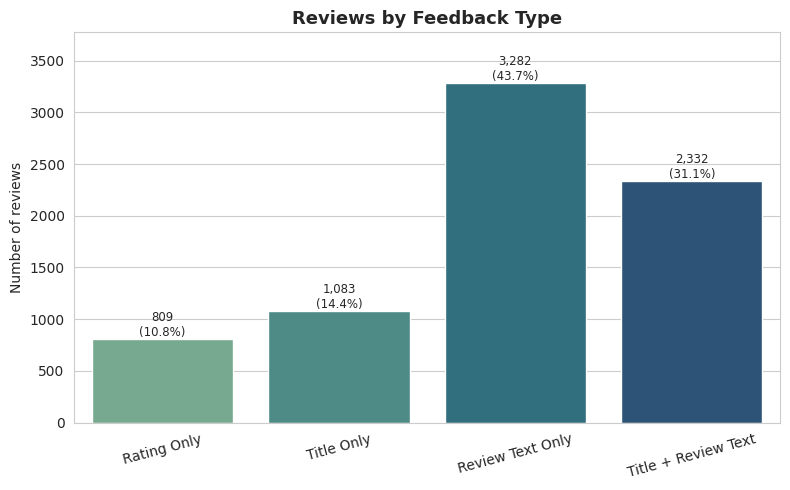

In [23]:
fb_order = ["Rating Only", "Title Only", "Review Text Only", "Title + Review Text"]
fb_counts = df["feedback_type"].value_counts().reindex(fb_order)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=fb_counts.index, y=fb_counts.values, palette=PALETTE, ax=ax,
            hue=fb_counts.index, legend=False)
annotate_bars(ax)
ax.set_title("Reviews by Feedback Type")
ax.set_xlabel("")
ax.set_ylabel("Number of reviews")
ax.margins(y=0.15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 20. Review volume over time (monthly)
Is feedback volume steady across 2025, or seasonal?

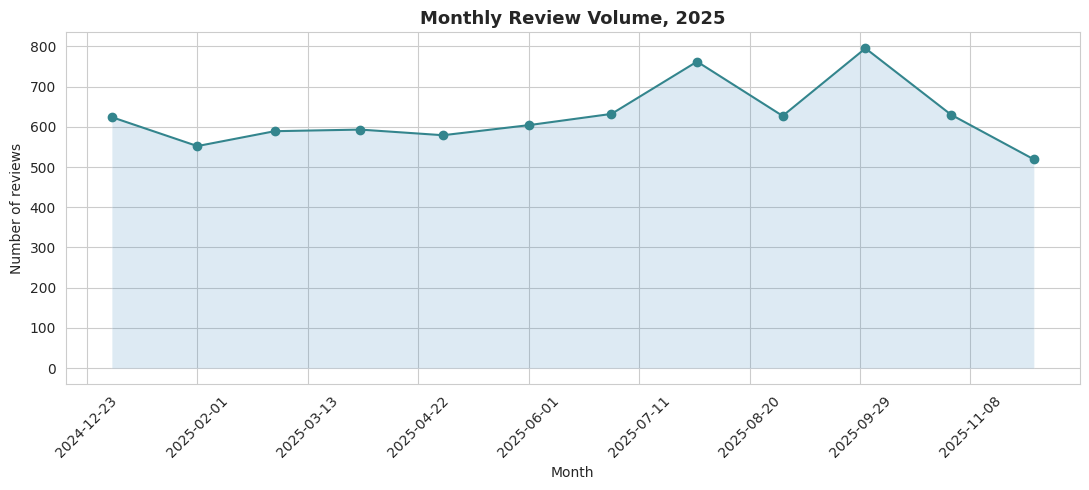

In [24]:
monthly = df.groupby(df["published_date"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly.values, marker="o", color=sns.color_palette(PALETTE, 1)[0])
ax.fill_between(monthly.index, monthly.values, alpha=0.15)
ax.set_title("Monthly Review Volume, 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
ax.xaxis.set_major_locator(mticker.MaxNLocator(12))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 21. Review volume by day of week

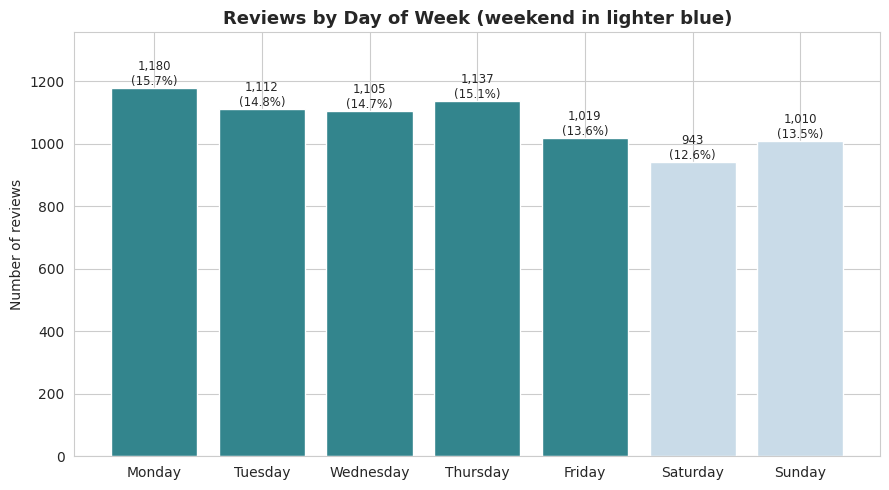

In [25]:
dow_counts = df["day_of_week"].value_counts().reindex(dow_order)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#c9dbe8" if d in ("Saturday", "Sunday") else sns.color_palette(PALETTE, 1)[0]
          for d in dow_order]
ax.bar(dow_counts.index, dow_counts.values, color=colors)
annotate_bars(ax)
ax.set_title("Reviews by Day of Week (weekend in lighter blue)")
ax.set_xlabel("")
ax.set_ylabel("Number of reviews")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


## 22. Reviews by quarter
A coarser seasonal view alongside the monthly trend.

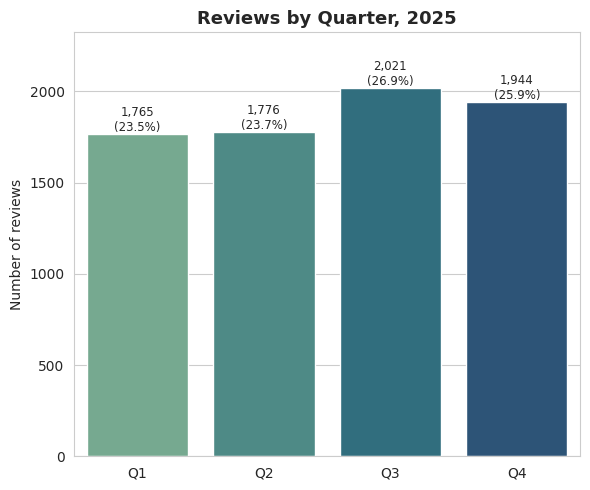

In [26]:
q_counts = df["quarter"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=[f"Q{q}" for q in q_counts.index], y=q_counts.values, palette=PALETTE, ax=ax,
            hue=[f"Q{q}" for q in q_counts.index], legend=False)
annotate_bars(ax)
ax.set_title("Reviews by Quarter, 2025")
ax.set_xlabel("")
ax.set_ylabel("Number of reviews")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


## 23. Review length — character count
Only applies to the 5,614 reviews with written text. Length is heavily right-skewed (most reviews are short, a few run past 1,000 characters), so this uses a log-scaled x-axis.

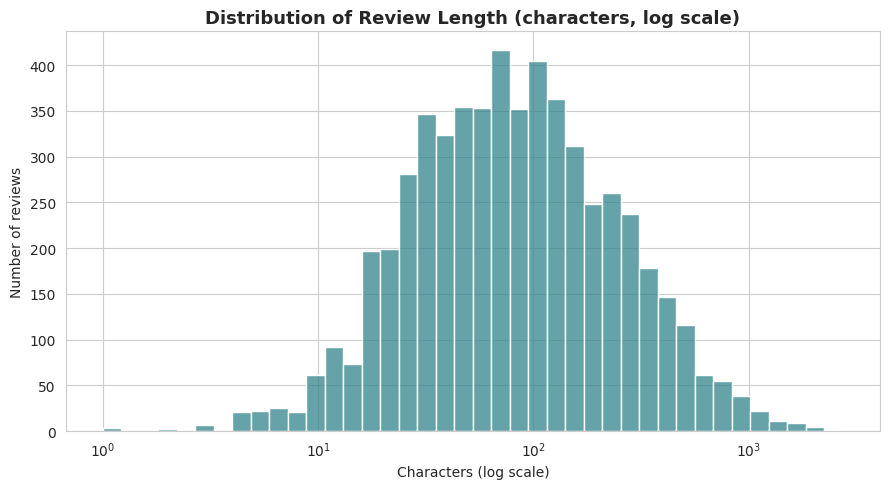

count    5614.000000
mean      143.978981
std       193.740496
min         1.000000
25%        37.000000
50%        78.000000
75%       170.000000
max      2735.000000
Name: review_char_count, dtype: float64


In [27]:
text_lengths = df["review_char_count"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(text_lengths, bins=40, log_scale=True, color=sns.color_palette(PALETTE, 1)[0], ax=ax)
ax.set_title("Distribution of Review Length (characters, log scale)")
ax.set_xlabel("Characters (log scale)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print(text_lengths.describe())


## 24. Review length — word count

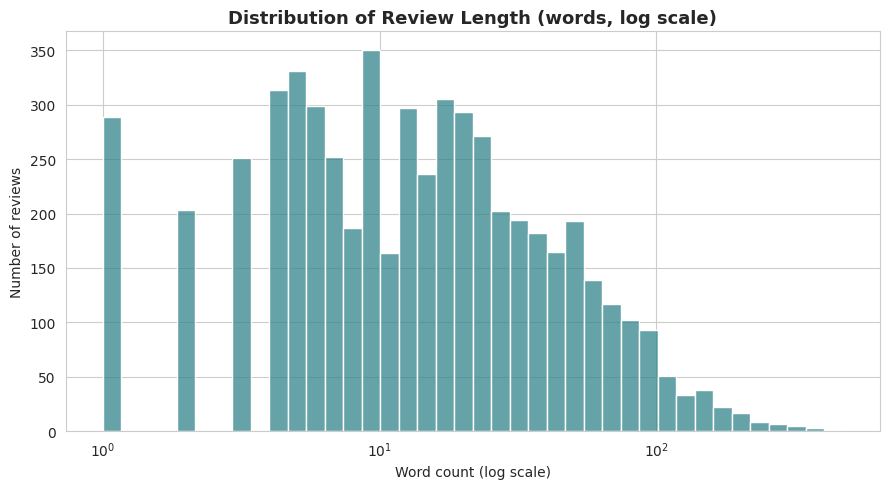

count    5614.000000
mean       24.431778
std        34.169403
min         1.000000
25%         6.000000
50%        13.000000
75%        29.000000
max       472.000000
Name: review_word_count, dtype: float64


In [28]:
word_counts = df["review_word_count"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(word_counts, bins=40, log_scale=True, color=sns.color_palette(PALETTE, 1)[0], ax=ax)
ax.set_title("Distribution of Review Length (words, log scale)")
ax.set_xlabel("Word count (log scale)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print(word_counts.describe())


## 25. Most common review titles
1,998 distinct titles appear across 3,415 non-empty entries — most are one-off free text, but a handful of recurring ones dominate (largely Booking.com's fixed rating categories: Exceptional, Very Good, Wonderful, Good, Fair).

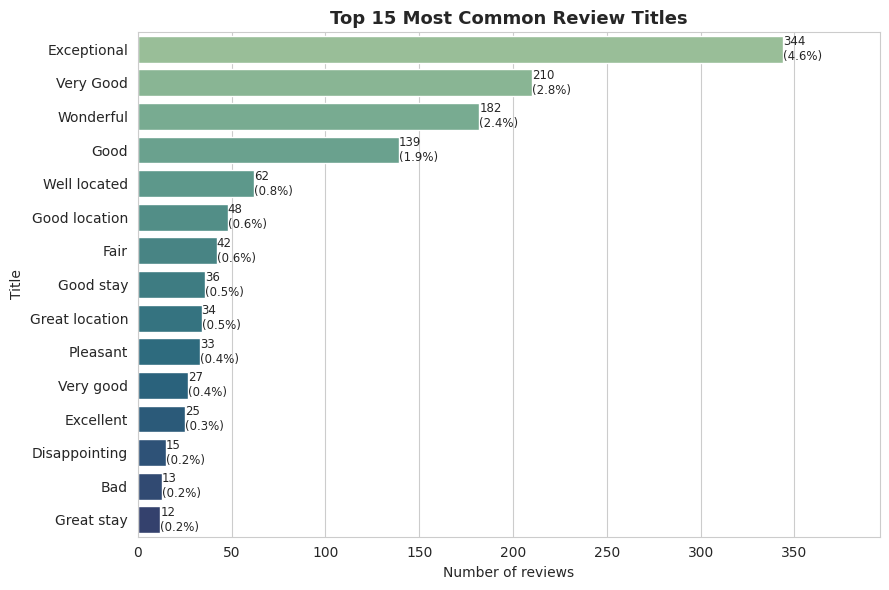

In [29]:
top_titles = df["title"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top_titles.values, y=top_titles.index, palette=PALETTE, ax=ax,
            hue=top_titles.index, legend=False)
annotate_bars(ax, horizontal=True)
ax.set_title("Top 15 Most Common Review Titles")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Title")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()


## Summary of univariate findings

- **Scores are heavily skewed positive**: ~62% of all reviews score a perfect 100, and Excellent (90-100) makes up ~72% of the dataset.
- **Review volume is dominated by a few platforms**: Google (~40%) and TrustYou Survey (~23%) together account for nearly two-thirds of all reviews; several platforms contribute only a handful.
- **Most reviews carry no written text**: over half of all rows are rating-only or title-only, meaning text-based analysis (sentiment, topics) will run on a subset of ~5,600 reviews.
- **Review volume looks roughly steady month-to-month**, worth checking against occupancy or seasonal travel patterns to explain any dips/peaks.
- **Written reviews are short**: median length is about 78 characters (roughly 15 words), with a long tail of a few much longer reviews.

Next: Part 3 looks at how these variables relate to each other.

# Part 3 — Bivariate & Multivariate Analysis

Continues directly from `df` above. **Score is the core outcome metric in this dataset**, so most comparisons below look at what moves it — source, time, feedback type, review length — before a couple of fully multivariate views (a correlation heatmap and a pairplot) that look at several variables together at once.

## 26. Setup — shared filters and color scheme
Several platforms have too few reviews (1-9) for spread-based charts like boxplots to mean anything, so those are filtered out here (they're already fully covered in the Part 2 volume chart). A consistent red→green color scheme is defined once for the ordered score categories.

In [30]:
MIN_SOURCE_N = 10
source_n = df["source"].value_counts()
big_sources = source_n[source_n >= MIN_SOURCE_N].index.tolist()
top5_sources = source_n.index[:5].tolist()

print(f"Sources with >= {MIN_SOURCE_N} reviews ({len(big_sources)}):")
print(big_sources)
print(f"\nExcluded (too few for spread-based charts): "
      f"{[s for s in source_n.index if s not in big_sources]}")

SCORE_COLORS = {"Bad": "#d73027", "Fair": "#fee08b", "Good": "#a6d96a", "Excellent": "#1a9850"}
score_palette = [SCORE_COLORS[c] for c in score_order]


Sources with >= 10 reviews (8):
['google.com', 'TrustYou Survey', 'booking.com', 'agoda.com', 'trip.com', 'tripadvisor.com', 'de.hotels.com', 'expedia.com']

Excluded (too few for spread-based charts): ['traveloka.com', 'travelocity.com', 'orbitz.com', 'hotel.interpark.com', 'holidaycheck.de', 'wotif.com']


## 27. Score by Source
Mean scores range from ~81 (Booking.com) to ~96 (Google) — a 15-point spread. Some of this is guest sentiment, but some is very likely platform rating culture and how each site's native scale (1-5 stars vs. 1-10) was converted to this 0-100 scale — worth keeping in mind rather than reading it as a pure satisfaction difference.

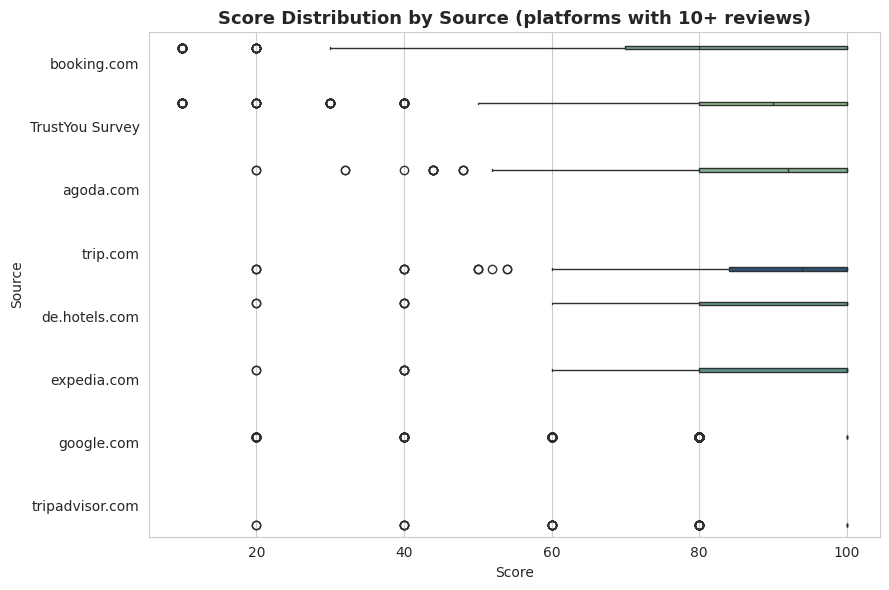

                 count       mean  median
source                                   
booking.com       1276  80.697492    80.0
TrustYou Survey   1729  87.698091    90.0
agoda.com          588  88.564626    92.0
trip.com           425  90.508235    94.0
de.hotels.com      139  87.625899   100.0
expedia.com        137  86.715328   100.0
google.com        3031  96.344441   100.0
tripadvisor.com    165  92.969697   100.0


In [31]:
plot_df = df[df["source"].isin(big_sources)]
order = plot_df.groupby("source", observed=True)["score"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=plot_df, y="source", x="score", order=order, palette=PALETTE, ax=ax,
            hue="source", legend=False)
ax.set_title("Score Distribution by Source (platforms with 10+ reviews)")
ax.set_xlabel("Score")
ax.set_ylabel("Source")
plt.tight_layout()
plt.show()

print(plot_df.groupby("source", observed=True)["score"].agg(["count", "mean", "median"]).loc[order])


## 28. Score Category Composition by Source
The boxplot above shows spread — this shows what share of each platform's reviews actually falls into each satisfaction band, sorted by % Excellent.

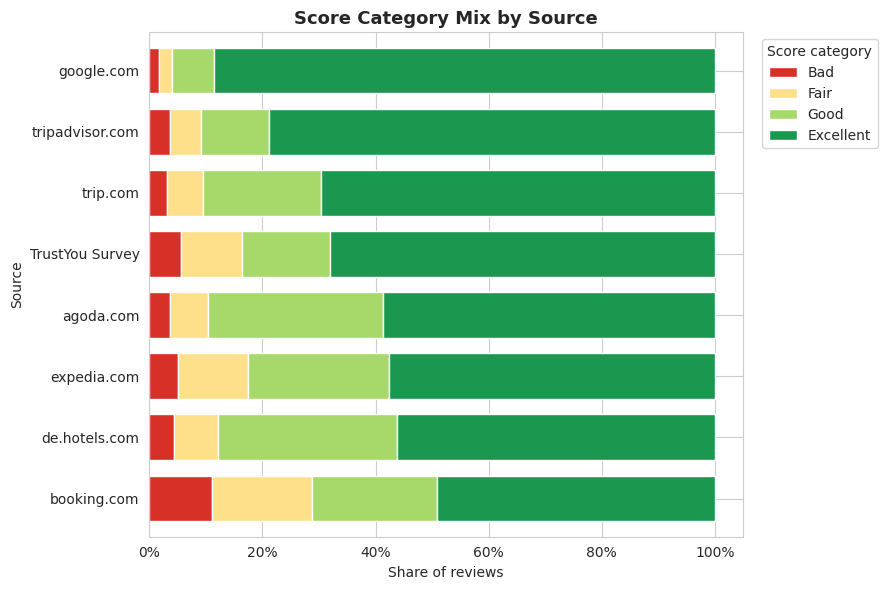

In [32]:
ct = pd.crosstab(plot_df["source"], plot_df["score_category"], normalize="index")[score_order]
ct = ct.loc[ct["Excellent"].sort_values().index]

fig, ax = plt.subplots(figsize=(9, 6))
ct.plot(kind="barh", stacked=True, color=score_palette, ax=ax, width=0.75)
ax.set_title("Score Category Mix by Source")
ax.set_xlabel("Share of reviews")
ax.set_ylabel("Source")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend(title="Score category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 29. Monthly Score Trend + Review Volume
Average score alongside review count on the same timeline, since a trend in one can be a lot easier to explain in light of the other. Average score drifts gently upward toward year-end (Nov ~92.5, vs. ~89 in Jan/Feb) — worth checking against any operational changes around that time, though a ~3-point shift within this data isn't a dramatic swing.

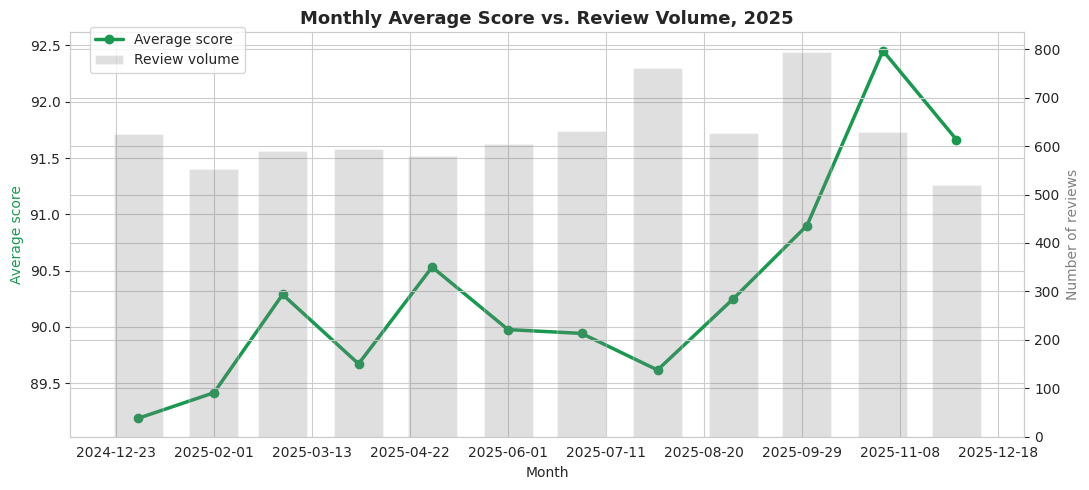

In [33]:
monthly_stats = df.groupby(df["published_date"].dt.to_period("M")).agg(
    avg_score=("score", "mean"), n=("score", "size")
)
monthly_stats.index = monthly_stats.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax2.bar(monthly_stats.index, monthly_stats["n"], width=20, alpha=0.25,
        color="gray", label="Review volume")
ax1.plot(monthly_stats.index, monthly_stats["avg_score"], marker="o", color="#1a9850",
         linewidth=2.5, label="Average score", zorder=3)

ax1.set_title("Monthly Average Score vs. Review Volume, 2025")
ax1.set_xlabel("Month")
ax1.set_ylabel("Average score", color="#1a9850")
ax2.set_ylabel("Number of reviews", color="gray")
ax1.xaxis.set_major_locator(mticker.MaxNLocator(12))
plt.xticks(rotation=45)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.95))
plt.tight_layout()
plt.show()


## 30. Score Category Composition by Month
The trend line above in category-mix form — is the year-end lift in average score coming from fewer Bad/Fair reviews, or more Excellent ones?

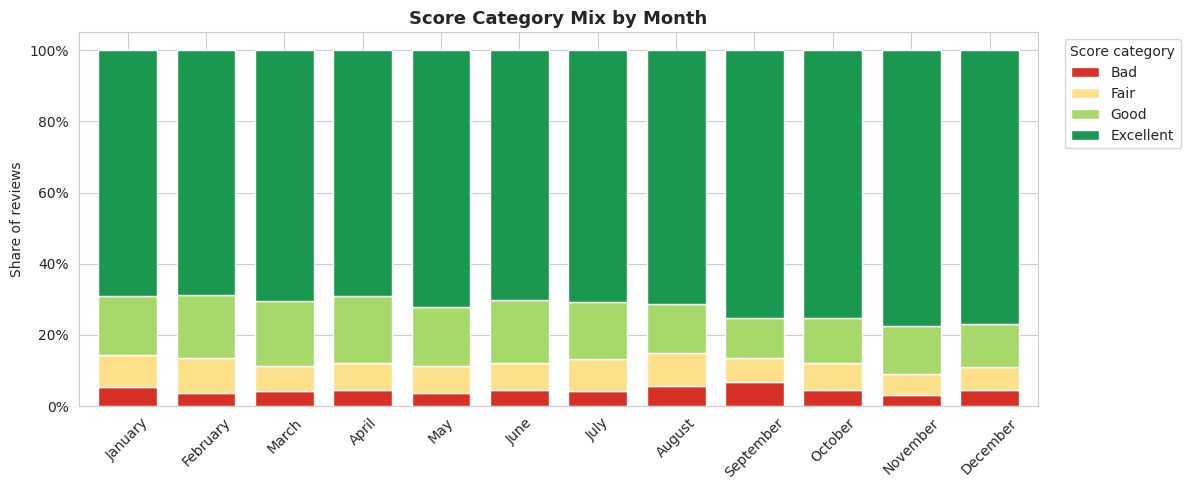

In [34]:
ct_month = pd.crosstab(df["month_name"], df["score_category"], normalize="index")[score_order]

fig, ax = plt.subplots(figsize=(12, 5))
ct_month.plot(kind="bar", stacked=True, color=score_palette, ax=ax, width=0.75)
ax.set_title("Score Category Mix by Month")
ax.set_xlabel("")
ax.set_ylabel("Share of reviews")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend(title="Score category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 31. Score by Day of Week
Average score barely moves across the week (89.0-91.1) — there isn't a meaningful weekday effect on satisfaction here, unlike the volume patterns in Part 2.

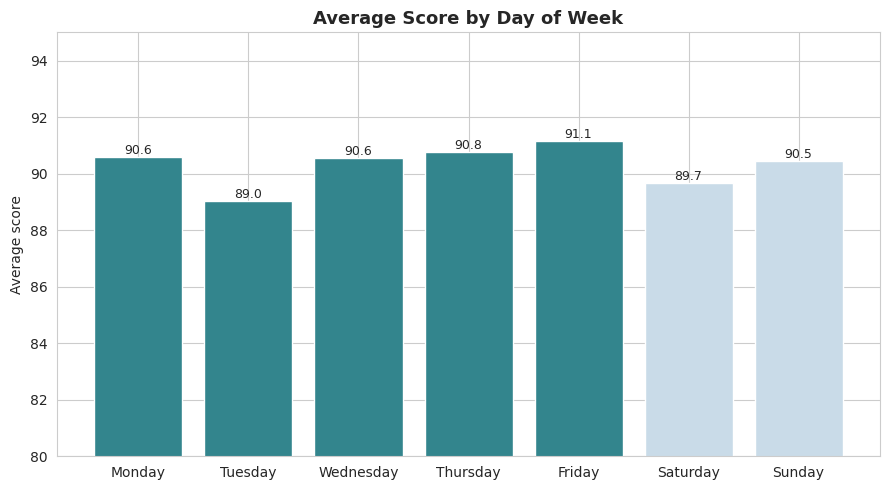

In [35]:
dow_score = df.groupby("day_of_week", observed=True)["score"].mean().reindex(dow_order)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#c9dbe8" if d in ("Saturday", "Sunday") else sns.color_palette(PALETTE, 1)[0]
          for d in dow_order]
ax.bar(dow_score.index, dow_score.values, color=colors)
ax.set_title("Average Score by Day of Week")
ax.set_xlabel("")
ax.set_ylabel("Average score")
ax.set_ylim(80, 95)
for i, v in enumerate(dow_score.values):
    ax.annotate(f"{v:.1f}", (i, v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


## 32. Score: Weekday vs. Weekend

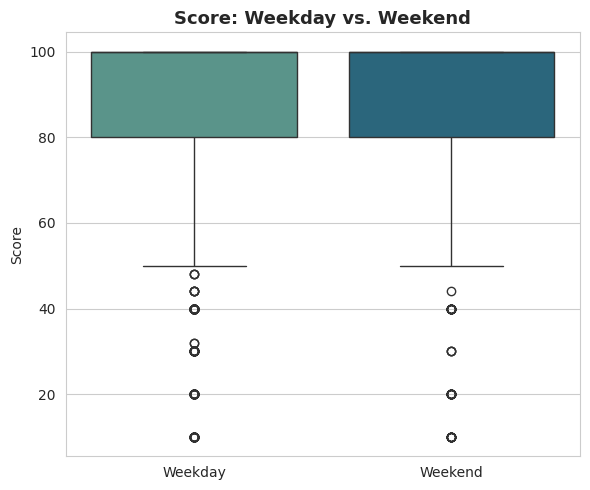

            count       mean  median
is_weekend                          
False        5553  90.404466   100.0
True         1953  90.077317   100.0


In [36]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="is_weekend", y="score", palette=PALETTE, ax=ax,
            hue="is_weekend", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Weekday", "Weekend"])
ax.set_title("Score: Weekday vs. Weekend")
ax.set_xlabel("")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

print(df.groupby("is_weekend")["score"].agg(["count", "mean", "median"]))


## 33. Score by Feedback Type
A somewhat counter-intuitive finding: **"Review Text Only" reviews score highest on average (~95.5)**, while "Title + Review Text" scores lowest (~84.6). This lines up with the source patterns above — "Review Text Only" is mostly short Google raves, while "Title + Review Text" is mostly Booking.com/Agoda/TripAdvisor reviews, which structurally invite more detailed (and often more critical) feedback.

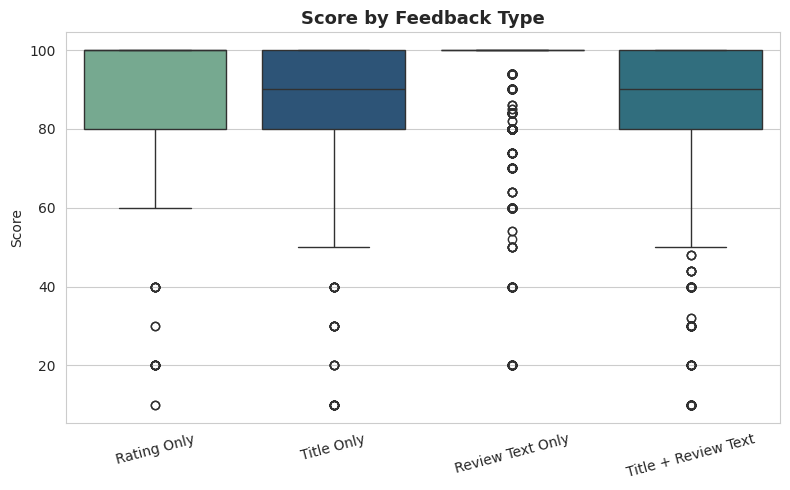

                     count       mean  median
feedback_type                                
Rating Only            809  90.951792   100.0
Title Only            1083  86.548476    90.0
Review Text Only      3282  95.491773   100.0
Title + Review Text   2332  84.571612    90.0


In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="feedback_type", y="score", order=fb_order, palette=PALETTE, ax=ax,
            hue="feedback_type", legend=False)
ax.set_title("Score by Feedback Type")
ax.set_xlabel("")
ax.set_ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(df.groupby("feedback_type", observed=True)["score"].agg(["count", "mean", "median"]).loc[fb_order])


## 34. Score vs. Review Length
A modest but real negative correlation (r ≈ -0.22 for characters, -0.23 for words): longer reviews trend toward lower scores. Not a strong relationship, but consistent with guests writing more when something went wrong.

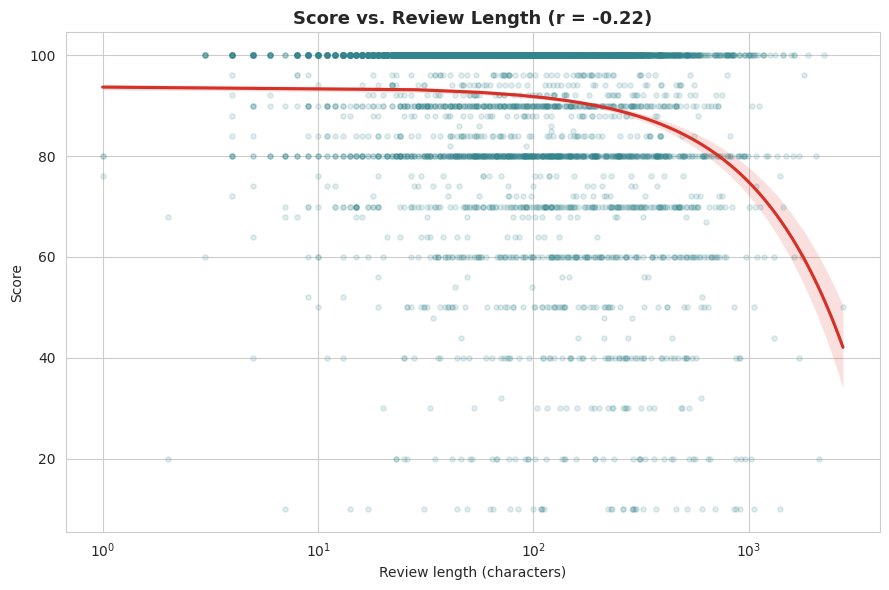

In [38]:
text_df = df.dropna(subset=["review_char_count"])
corr_char = text_df["score"].corr(text_df["review_char_count"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=text_df, x="review_char_count", y="score",
            scatter_kws={"alpha": 0.15, "s": 14, "color": sns.color_palette(PALETTE, 1)[0]},
            line_kws={"color": "#d73027"}, ax=ax)
ax.set_title(f"Score vs. Review Length (r = {corr_char:.2f})")
ax.set_xlabel("Review length (characters)")
ax.set_ylabel("Score")
ax.set_xscale("log")
plt.tight_layout()
plt.show()


## 35. Review Length by Score Category
The same relationship from the other direction — **Bad reviews average 268 characters vs. just 122 for Excellent ones**, more than double. Unhappy guests write noticeably more.

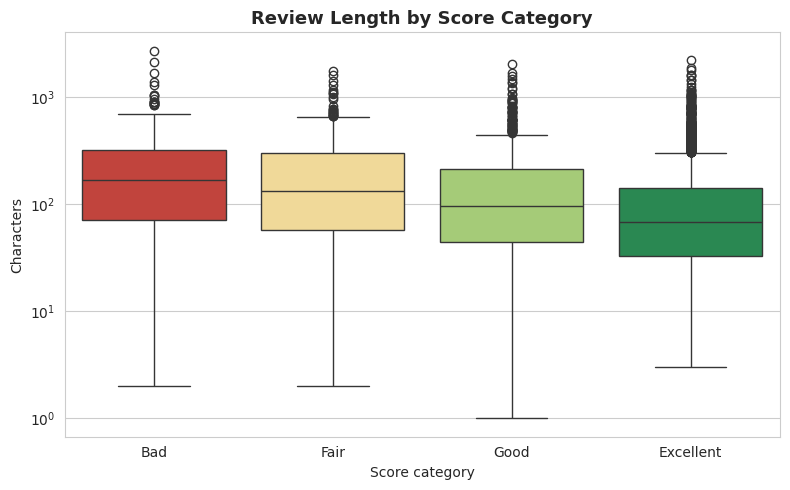

                count        mean  median
score_category                           
Bad               262  267.877863   169.0
Fair              404  225.272277   133.5
Good              792  176.002525    97.0
Excellent        4156  122.163138    69.0


In [39]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=text_df, x="score_category", y="review_char_count", order=score_order,
            palette=score_palette, ax=ax, hue="score_category", legend=False)
ax.set_title("Review Length by Score Category")
ax.set_xlabel("Score category")
ax.set_ylabel("Characters")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

print(text_df.groupby("score_category", observed=True)["review_char_count"].agg(["count", "mean", "median"]).loc[score_order])


## 36. Review Length by Source
Which platforms' guests write the most? (Filtered to the same 10+ review sources as above, and only rows that actually have text.)

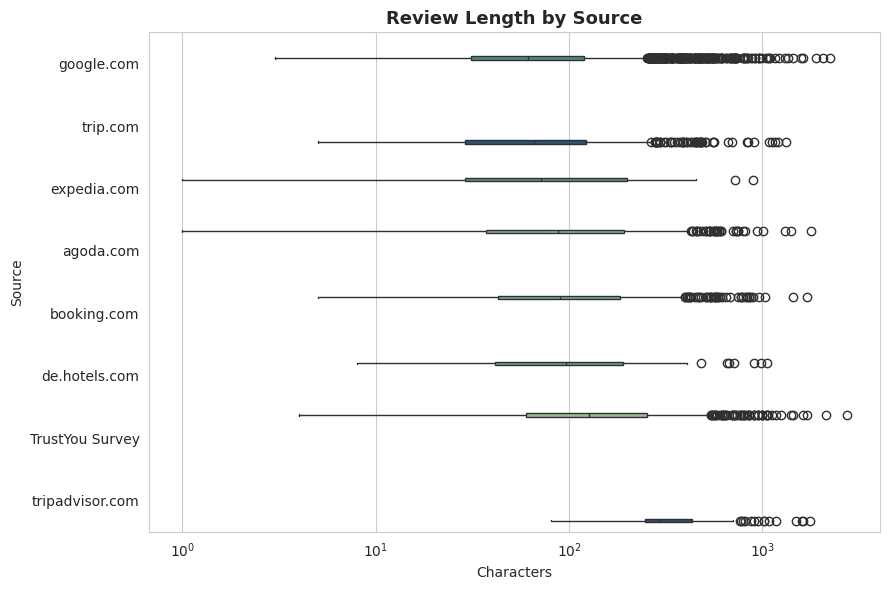

In [40]:
text_plot_df = plot_df.dropna(subset=["review_char_count"])
len_order = text_plot_df.groupby("source", observed=True)["review_char_count"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=text_plot_df, y="source", x="review_char_count", order=len_order,
            palette=PALETTE, ax=ax, hue="source", legend=False)
ax.set_title("Review Length by Source")
ax.set_xlabel("Characters")
ax.set_ylabel("Source")
ax.set_xscale("log")
plt.tight_layout()
plt.show()


## 37. Review Volume by Source Over Time
How the top 5 sources' monthly volume compares — is any platform growing or shrinking as a share of total feedback across the year?

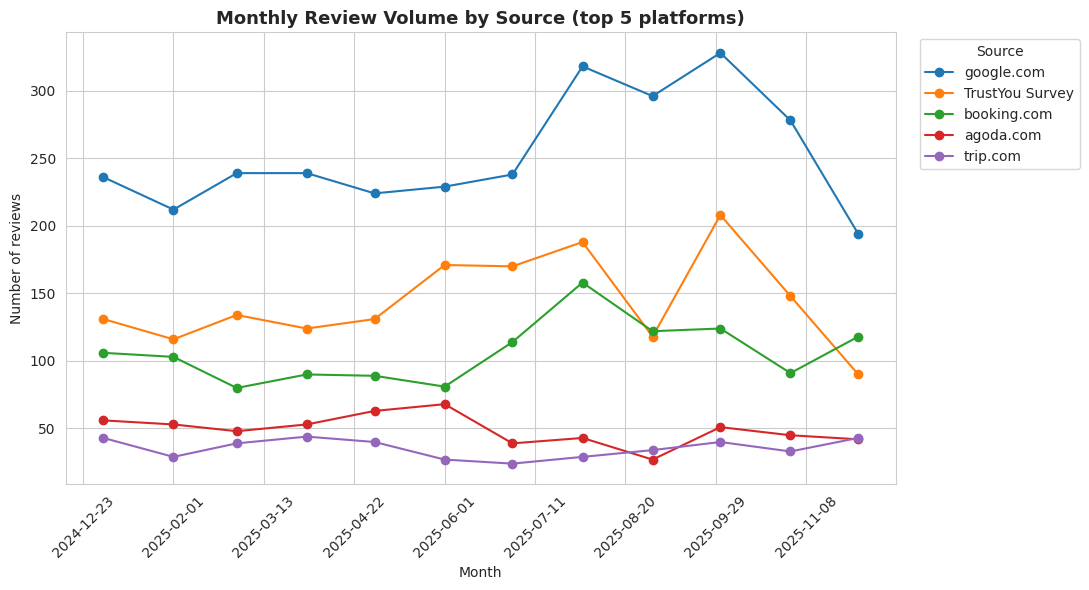

In [41]:
top5_monthly = (
    df[df["source"].isin(top5_sources)]
    .groupby([df["published_date"].dt.to_period("M"), "source"], observed=True)
    .size()
    .unstack(fill_value=0)
)
top5_monthly.index = top5_monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 6))
for src in top5_sources:
    ax.plot(top5_monthly.index, top5_monthly[src], marker="o", label=src)
ax.set_title("Monthly Review Volume by Source (top 5 platforms)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of reviews")
ax.xaxis.set_major_locator(mticker.MaxNLocator(12))
ax.legend(title="Source", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 38. Source × Feedback Type
Each platform has a very distinct feedback "shape" — Agoda and TripAdvisor are ~100% Title+Review Text, Trip.com is ~100% Review Text Only, Google is 88% Review Text Only / 12% Rating Only, and Booking splits almost evenly between Title Only and Title+Review Text. This is a structural/platform-design pattern, not a guest behavior difference.

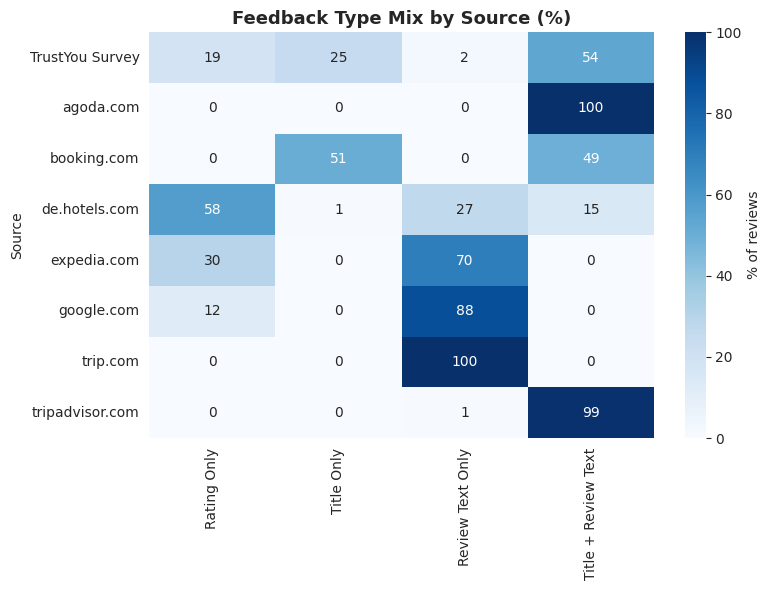

In [42]:
ct_fb = pd.crosstab(plot_df["source"], plot_df["feedback_type"], normalize="index")[fb_order]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(ct_fb * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of reviews"}, ax=ax)
ax.set_title("Feedback Type Mix by Source (%)")
ax.set_xlabel("")
ax.set_ylabel("Source")
plt.tight_layout()
plt.show()


## 39. Quarterly Average Score by Top 5 Sources
Combines three variables at once — quarter, source, and score — to check whether any platform's guest sentiment moved meaningfully across the year rather than just looking at the property-wide trend.

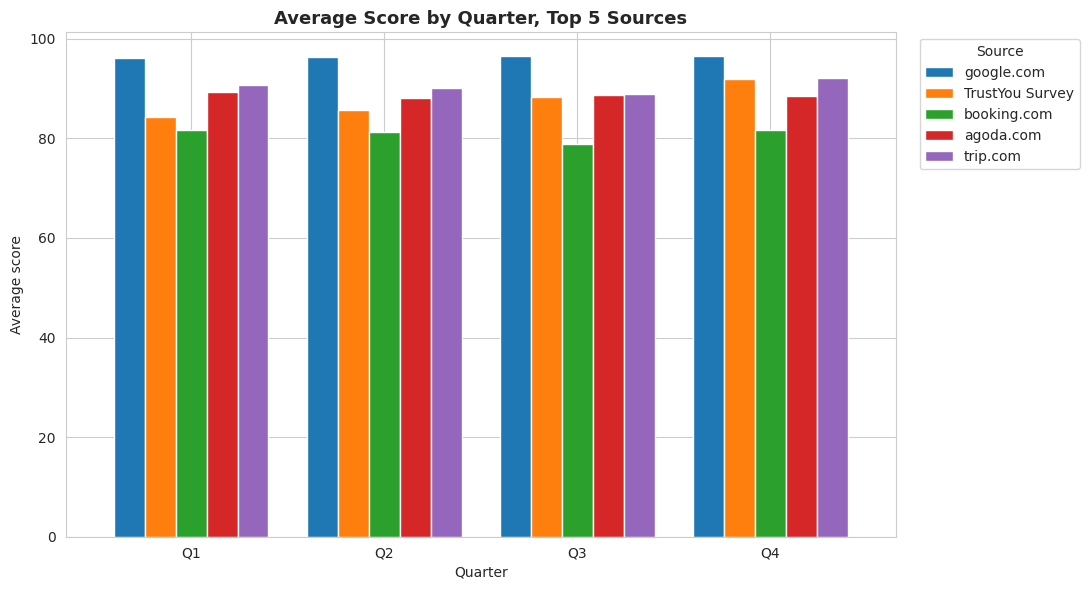

In [43]:
q_src = (
    df[df["source"].isin(top5_sources)]
    .groupby(["quarter", "source"], observed=True)["score"]
    .mean()
    .unstack()
)[top5_sources]

fig, ax = plt.subplots(figsize=(11, 6))
q_src.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Average Score by Quarter, Top 5 Sources")
ax.set_xlabel("Quarter")
ax.set_ylabel("Average score")
ax.set_xticklabels([f"Q{q}" for q in q_src.index], rotation=0)
ax.legend(title="Source", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 40. Correlation Heatmap of Numeric Variables
A single summary view of how score, review length, and calendar position relate to each other. `is_weekend` is converted to 0/1 to include it.

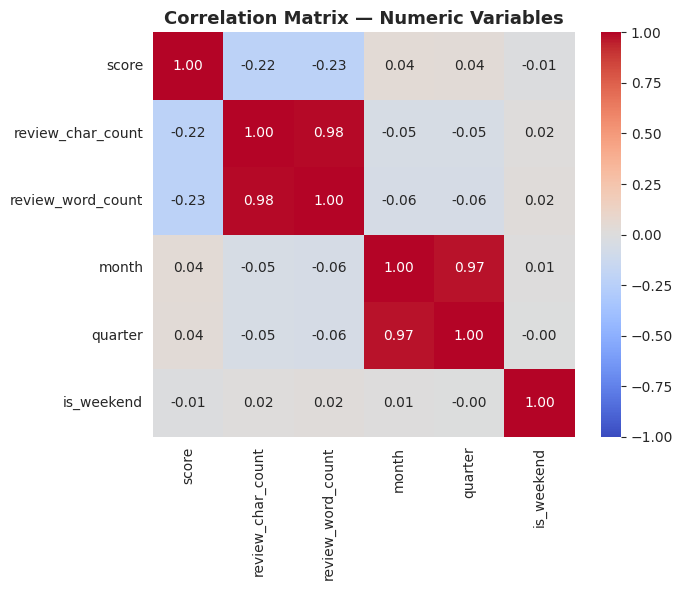

In [44]:
numeric_df = df[["score", "review_char_count", "review_word_count", "month", "quarter"]].copy()
numeric_df["is_weekend"] = df["is_weekend"].astype(int)
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Matrix — Numeric Variables")
plt.tight_layout()
plt.show()


## 41. Multivariate View: Score, Length, and Category Together
A pairplot looking at score, character count, and word count simultaneously, colored by score category — the one chart in this notebook showing four variables at once. The Excellent (green) cluster sits visibly toward shorter, lower-word-count reviews; Bad (red) points spread further right into longer reviews, consistent with everything above.

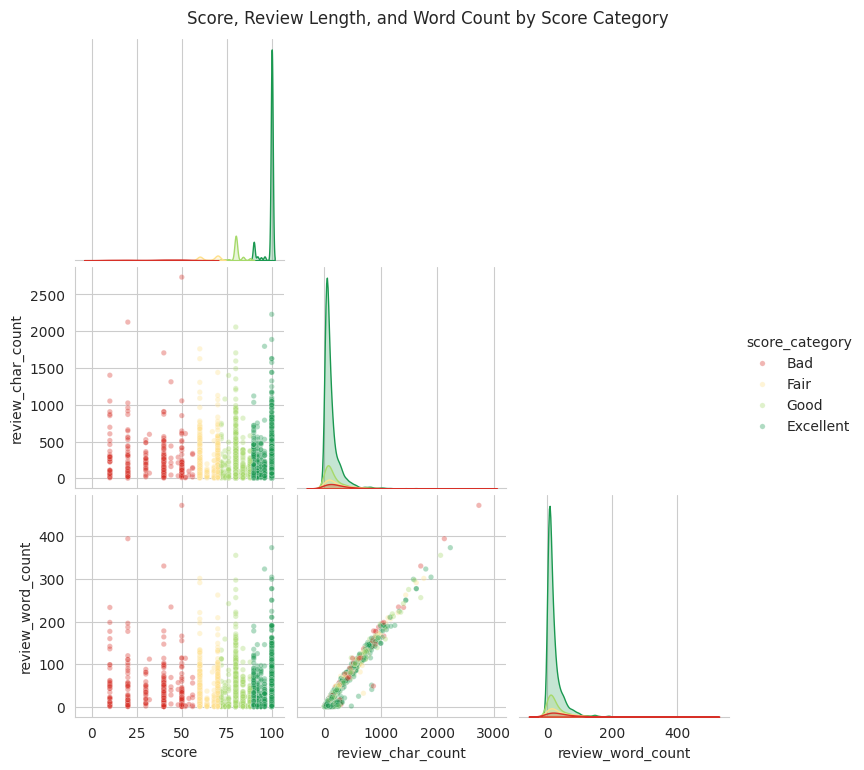

In [45]:
pair_df = df.dropna(subset=["review_char_count"])[
    ["score", "review_char_count", "review_word_count", "score_category"]
]

g = sns.pairplot(pair_df, hue="score_category", hue_order=score_order,
                  palette=SCORE_COLORS, corner=True,
                  plot_kws={"alpha": 0.35, "s": 15})
g.figure.suptitle("Score, Review Length, and Word Count by Score Category", y=1.02)
plt.show()


## Summary of bivariate & multivariate findings

- **Source is the strongest driver of score differences**: mean scores range from ~81 (Booking.com) to ~96 (Google), a 15-point spread — likely a mix of real guest sentiment and platform-specific rating culture/scale conversion.
- **Feedback type matters more than expected**: "Review Text Only" reviews (mostly short Google raves) average ~95.5, while "Title + Review Text" reviews (mostly Booking/Agoda/TripAdvisor, which prompt more detailed feedback) average ~84.6.
- **Longer reviews skew more negative**: a consistent (if moderate, r≈-0.22) negative correlation between review length and score, and Bad reviews run more than double the length of Excellent ones on average (268 vs. 122 characters).
- **Day of week and weekday/weekend have almost no effect on score** (89-91 range throughout) — timing drives review *volume* patterns (see Part 2) but not *sentiment*.
- **Average score drifts up gently toward year-end** (Nov ~92.5 vs. Jan/Feb ~89), while the category-mix chart shows this comes from a shrinking Bad/Fair share more than a growing Excellent share.
- **Each platform has a distinct, structural feedback "shape"** (e.g., Agoda/TripAdvisor almost always collect both a title and text; Trip.com only collects text) — this is a platform design pattern worth remembering before comparing sentiment across sources.

**Natural next steps**: text-based analysis (sentiment scoring, topic/keyword extraction, language detection) on the ~5,600 reviews with written text, and a closer look at what's actually said in the small Bad/Fair segment.

# Part 4 — Text & Sentiment Analysis

This is the richest part of the dataset: the 5,614 reviews that have written text. This section covers language composition, sentiment scoring, keyword/topic extraction, aspect-level breakdowns, and a qualitative look at the lowest-scoring reviews.

**A note on scope**: this dataset is genuinely multilingual — roughly 18% of written reviews use non-Latin scripts (Arabic, Thai, Chinese, Korean, etc.), and even the Latin-script portion includes some French, Swedish, and other European languages mixed in with English. Sentiment scoring and keyword extraction below are run on the **English-detected subset only** (language detection is what identifies it) — this is a deliberate accuracy trade-off, since sentiment lexicons and stopword lists are English-tuned and would produce misleading results on other languages. Aspect tagging is the exception — it's pattern-matched directly and naturally skips non-English text without needing the language column.

**Two cells below (43 and 45) install and use `langdetect`/`textblob`, which need an internet connection** — this works automatically in Colab, but I want to flag that these two specific cells are the only ones in the whole notebook I could not execute and verify myself before sending this to you (my own sandbox has no internet access). They use standard, well-documented APIs, but if either one errors, share the message and I'll fix it — same as we did with the earlier variable issues.

## 42. Install language + sentiment packages
One-time install. `langdetect` is small and self-contained (no separate model download); `textblob`'s basic polarity scoring also works out of the box with no extra corpus download.

In [46]:
!pip install -q langdetect textblob


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 43. Language detection
Applied to every review with text. Very short text (e.g. a single word) can occasionally fail to detect reliably — those are labeled `"unknown"` rather than raising an error.

Detected languages across 5,614 written reviews:
language
en       3920
ar        351
th        289
ko        172
fr        121
zh-tw      71
ja         61
vi         52
hr         52
de         51
id         44
so         40
it         35
he         34
cy         33
Name: count, dtype: int64


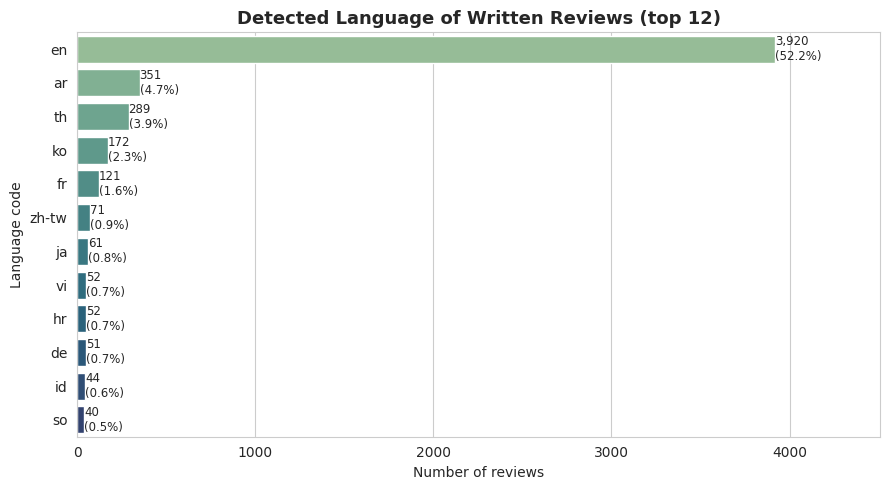

In [47]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0  # makes langdetect deterministic

def safe_detect(text):
    try:
        return detect(text)
    except Exception:
        return "unknown"

df["language"] = None
has_text_mask = df["review_text"].notna()
df.loc[has_text_mask, "language"] = df.loc[has_text_mask, "review_text_clean"].apply(safe_detect)

lang_counts = df.loc[has_text_mask, "language"].value_counts()
print(f"Detected languages across {has_text_mask.sum():,} written reviews:")
print(lang_counts.head(15))

fig, ax = plt.subplots(figsize=(9, 5))
top_langs = lang_counts.head(12)
sns.barplot(x=top_langs.values, y=top_langs.index, palette=PALETTE, ax=ax,
            hue=top_langs.index, legend=False)
annotate_bars(ax, horizontal=True)
ax.set_title("Detected Language of Written Reviews (top 12)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Language code")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()


## 44. Score by Detected Language
Do English-language reviewers rate differently than non-English reviewers? Restricted to languages with at least 20 reviews for a meaningful comparison.

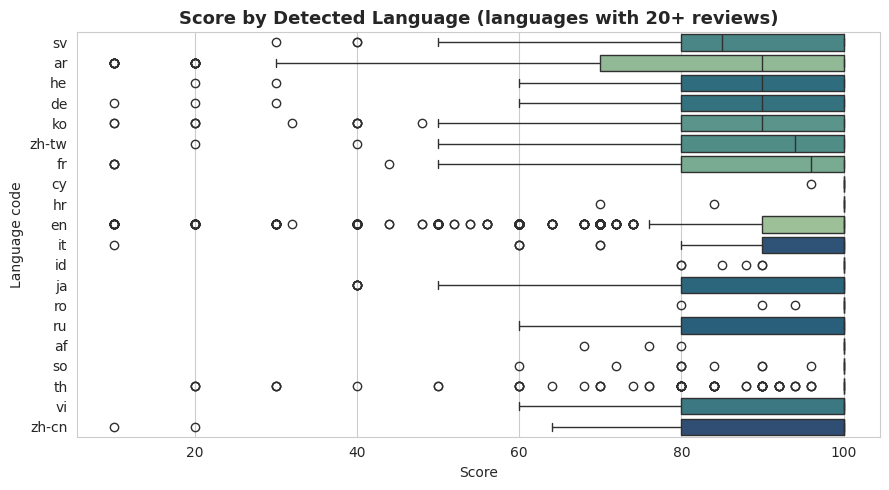

          count       mean  median
language                          
sv           30  82.666667    85.0
ar          351  81.948718    90.0
he           34  86.058824    90.0
de           51  85.901961    90.0
ko          172  84.546512    90.0
zh-tw        71  88.225352    94.0
fr          121  84.809917    96.0
cy           33  99.878788   100.0
hr           52  99.115385   100.0
en         3920  91.815051   100.0
it           35  90.857143   100.0
id           44  98.022727   100.0
ja           61  85.803279   100.0
ro           21  98.285714   100.0
ru           31  89.870968   100.0
af           20  96.200000   100.0
so           40  95.800000   100.0
th          289  94.595156   100.0
vi           52  91.346154   100.0
zh-cn        31  88.774194   100.0


In [48]:
lang_n = df.loc[has_text_mask, "language"].value_counts()
big_langs = lang_n[lang_n >= 20].index.tolist()

fig, ax = plt.subplots(figsize=(9, 5))
order = df[df["language"].isin(big_langs)].groupby("language")["score"].median().sort_values().index
sns.boxplot(data=df[df["language"].isin(big_langs)], y="language", x="score", order=order,
            palette=PALETTE, ax=ax, hue="language", legend=False)
ax.set_title("Score by Detected Language (languages with 20+ reviews)")
ax.set_xlabel("Score")
ax.set_ylabel("Language code")
plt.tight_layout()
plt.show()

print(df[df["language"].isin(big_langs)].groupby("language")["score"].agg(["count", "mean", "median"]).loc[order])


## 45. Sentiment Analysis (English reviews)
TextBlob polarity ranges from -1 (very negative) to +1 (very positive). Run only on the English-detected subset for the accuracy reasons noted above.

English-language reviews scored: 3,920


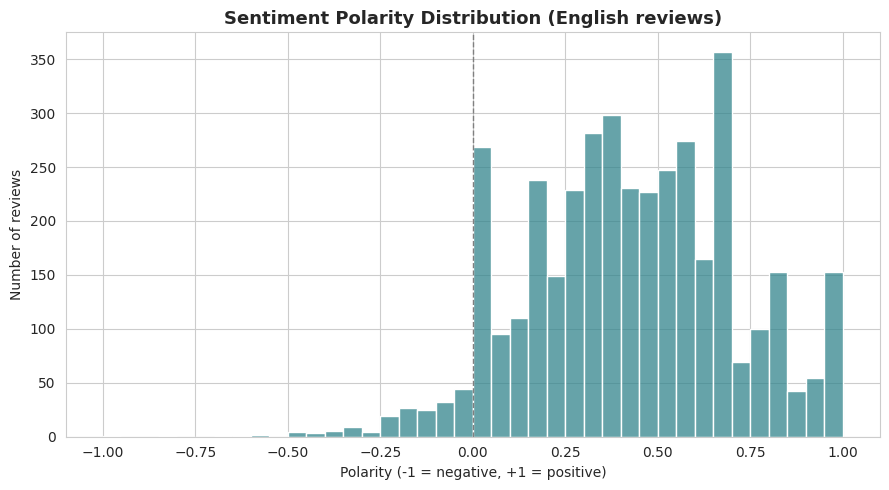

count    3920.000000
mean        0.428139
std         0.284378
min        -1.000000
25%         0.233333
50%         0.433333
75%         0.642813
max         1.000000
Name: sentiment_polarity, dtype: float64


In [49]:
from textblob import TextBlob

en_mask = df["language"] == "en"
df["sentiment_polarity"] = np.nan
df.loc[en_mask, "sentiment_polarity"] = df.loc[en_mask, "review_text_clean"].apply(
    lambda t: TextBlob(t).sentiment.polarity
)

print(f"English-language reviews scored: {en_mask.sum():,}")

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df.loc[en_mask, "sentiment_polarity"], bins=40, color=sns.color_palette(PALETTE, 1)[0], ax=ax)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Sentiment Polarity Distribution (English reviews)")
ax.set_xlabel("Polarity (-1 = negative, +1 = positive)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

print(df.loc[en_mask, "sentiment_polarity"].describe())


## 46. Sentiment vs. Numeric Score (validation)
If TextBlob's text-based sentiment roughly agrees with the platform's own numeric score, that's a good sanity check that both signals are picking up something real.

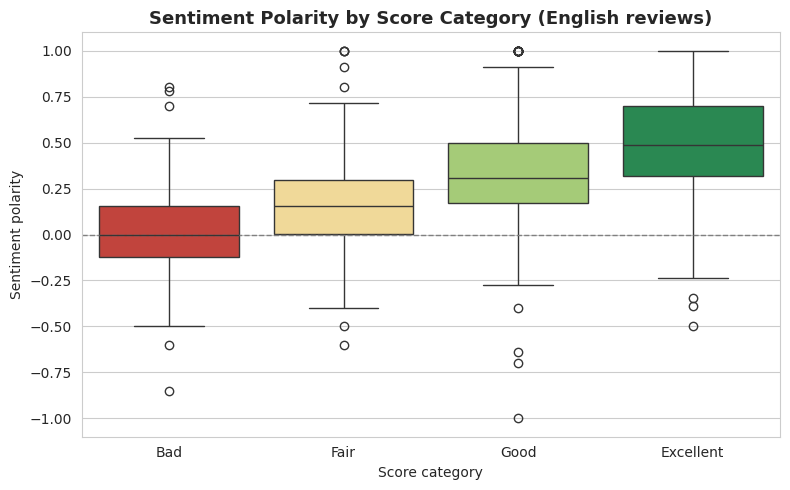

Correlation between numeric score and text sentiment: r = 0.44


In [50]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df[en_mask], x="score_category", y="sentiment_polarity", order=score_order,
            palette=score_palette, ax=ax, hue="score_category", legend=False)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Sentiment Polarity by Score Category (English reviews)")
ax.set_xlabel("Score category")
ax.set_ylabel("Sentiment polarity")
plt.tight_layout()
plt.show()

corr_sent = df.loc[en_mask, ["score", "sentiment_polarity"]].corr().iloc[0, 1]
print(f"Correlation between numeric score and text sentiment: r = {corr_sent:.2f}")


## 47. Most Common Words & Phrases
Top unigrams/bigrams across English-language reviews, with common stopwords removed. A few names stand out repeatedly (guests calling out specific staff members by name) — worth reading literally rather than just as generic "helpful staff" language.

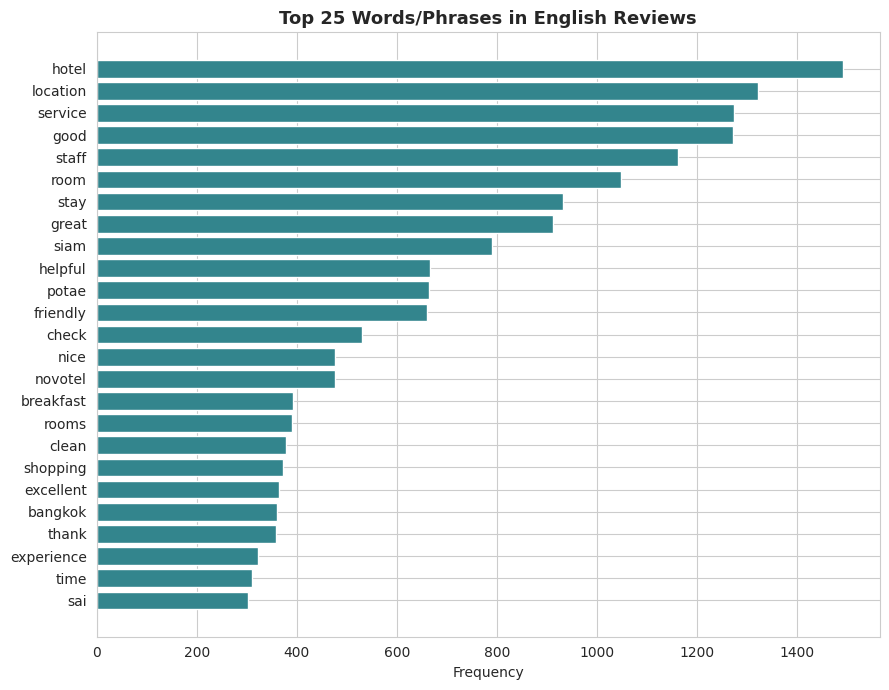

In [51]:
from sklearn.feature_extraction.text import CountVectorizer

en_text = df.loc[en_mask, "review_text_clean"]
en_text = en_text[en_text.str.len() > 0]

vec = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_features=25)
X = vec.fit_transform(en_text)
freqs = np.asarray(X.sum(axis=0)).ravel()
top_terms = pd.Series(freqs, index=vec.get_feature_names_out()).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_terms.index, top_terms.values, color=sns.color_palette(PALETTE, 1)[0])
ax.set_title("Top 25 Words/Phrases in English Reviews")
ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()


## 48. Aspect-Based Tagging
Simple keyword matching (not ML) against 8 common hotel-review themes, run across all review text — non-English text simply won't match these English keywords, so this naturally scopes itself without needing the language column. Two views: how often each aspect comes up, and how guests who mention it actually score.

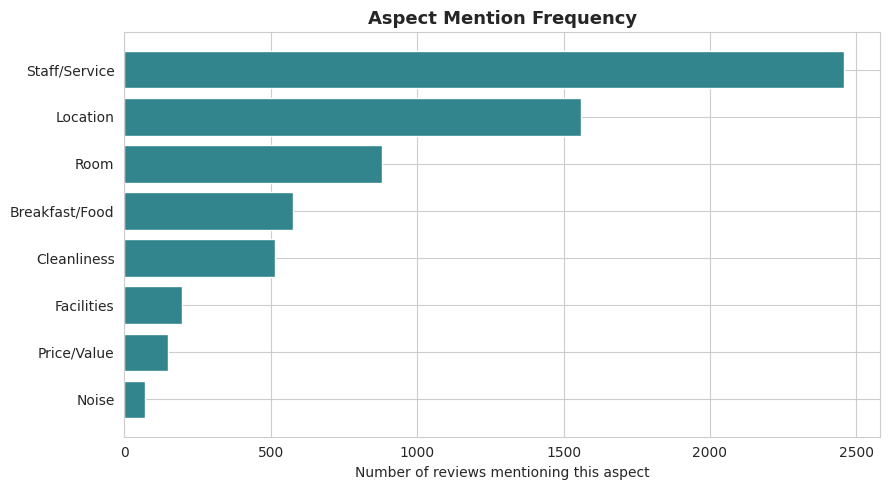

In [52]:
ASPECTS = {
    "Location": r"\b(?:location|located|situated|walk(?:ing)? distance|near|close to|shopping|mall|bts|skytrain|mrt)\b",
    "Staff/Service": r"\b(?:staff|service|friendly|helpful|welcoming|receptionist|front desk|concierge)\b",
    "Room": r"\b(?:room|bed|bathroom|shower|view|spacious)\b",
    "Cleanliness": r"\b(?:clean|cleanliness|dirty|smell|housekeeping)\b",
    "Breakfast/Food": r"\b(?:breakfast|buffet|food|restaurant|dining)\b",
    "Price/Value": r"\b(?:price|value|expensive|cheap|worth|money)\b",
    "Facilities": r"\b(?:pool|gym|spa|wifi|wi-fi|internet|elevator|lift)\b",
    "Noise": r"\b(?:noise|noisy|loud)\b",
}

text_clean = df["review_text_clean"].fillna("")
aspect_rows = {}
for aspect, pattern in ASPECTS.items():
    mask = text_clean.str.contains(pattern, case=False, regex=True, na=False)
    aspect_rows[aspect] = {"mentions": int(mask.sum()), "avg_score": df.loc[mask, "score"].mean()}

aspect_df = pd.DataFrame(aspect_rows).T
aspect_df = aspect_df.sort_values("mentions", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(aspect_df.index, aspect_df["mentions"], color=sns.color_palette(PALETTE, 1)[0])
ax.set_title("Aspect Mention Frequency")
ax.set_xlabel("Number of reviews mentioning this aspect")
plt.tight_layout()
plt.show()


## 49. Average Score by Aspect Mentioned
This is the more actionable view — **Noise (~68) and Price/Value (~75) stand out as the lowest-scoring aspects**, well below the ~90 overall average, while Staff/Service mentions actually skew *above* average (~94). Staff are a clear strength; noise and value perception are the areas most worth investigating operationally.

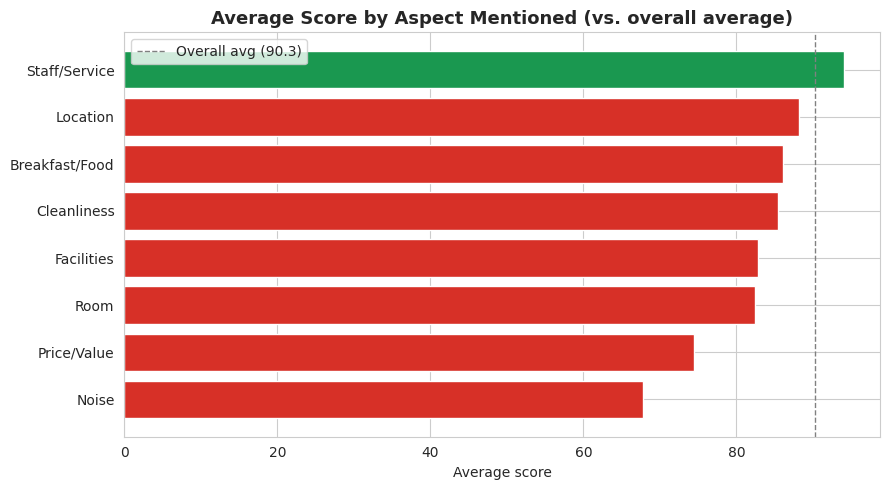

                mentions  avg_score
Noise               71.0  67.746479
Price/Value        148.0  74.513514
Room               879.0  82.440273
Facilities         197.0  82.832487
Cleanliness        516.0  85.403101
Breakfast/Food     577.0  86.110919
Location          1561.0  88.231262
Staff/Service     2458.0  94.076892


In [53]:
aspect_df_sorted = aspect_df.sort_values("avg_score")
overall_avg = df["score"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#d73027" if v < overall_avg else "#1a9850" for v in aspect_df_sorted["avg_score"]]
ax.barh(aspect_df_sorted.index, aspect_df_sorted["avg_score"], color=colors)
ax.axvline(overall_avg, color="gray", linestyle="--", linewidth=1, label=f"Overall avg ({overall_avg:.1f})")
ax.set_title("Average Score by Aspect Mentioned (vs. overall average)")
ax.set_xlabel("Average score")
ax.legend()
plt.tight_layout()
plt.show()

print(aspect_df.sort_values("avg_score"))


## 50. Low-Score Deep Dive
The quantitative patterns above come from somewhere — this reads the actual lowest-scoring written reviews directly. Real examples already in this data include a burst water pipe in the lobby, long lift waits, and a complaint about advertised kids' activities not existing (this last one is in French, a reminder that some of the most useful feedback sits outside the English-only sentiment/keyword analysis above).

In [54]:
lowest = df[df["review_text"].notna()].sort_values("score").head(15)

for _, row in lowest.iterrows():
    print(f"[{row['source']} | score={row['score']:.0f} | {row['published_date'].date()}]")
    print(f"  {row['review_text'][:200]}")
    print()


[booking.com | score=10 | 2025-11-04]
  الموظفين قمة الاحترام والاخلاق وبشوشين والابتسامة دائما في وجوههم.
الغرف قديمه

[TrustYou Survey | score=10 | 2025-12-27]
  Rating: 1/10

I recently stayed at Novotel Bangkok on Siam Square, and it was a huge disappointment. Last year I stayed at the InterContinental Hua Hin Resort, which was easily a 9/10—this experience 

[booking.com | score=10 | 2025-09-03]
  had a very disappointing stay at this hotel. Everything was below standard – the cleanliness was poor, the rooms were uncomfortable, and the prices were not worth it at all.

To make things worse, the

[TrustYou Survey | score=10 | 2025-06-09]
  My name is Sangwook Lee, and I stayed at your hotel in Room 819 from June 2 to June 6 (4 nights)
The total charge for my stay was 1,133,504 KRW
Could you please send me an official invoice for this st

[TrustYou Survey | score=10 | 2025-09-03]
  도시전망뷰는 실외기가 보이며 호텔 안에서부터 소독약냄새와 샴푸와바디샴푸만잇음 여성인경우는 어찌하나요 샤워부스타일이 다깨지고 닫히지도않고 엘리베이터는 원할하지않고 각국에 매너없는 손님들

## Summary of text & sentiment findings

- **The dataset is genuinely multilingual**: ~18% of written reviews use non-Latin scripts (Arabic, Thai, Chinese, Korean), plus some French/Swedish/other European languages in Latin script — worth keeping in mind for any text-based analysis, since English-tuned tools (used here) only cover part of the data.
- **Text sentiment broadly agrees with the numeric score** — a meaningful positive correlation between TextBlob polarity and the platform score, which is a reasonable sanity check that both signals reflect real guest sentiment rather than noise.
- **Staff are the standout strength**: "Staff/Service" is both the most-mentioned aspect (2,458 reviews) and scores well above average (~94) — several individual staff members are named repeatedly in reviews (visible in the top-terms chart), which is worth surfacing to hotel management directly, by name.
- **Noise and price/value are the clearest pain points**: both score well below the property-wide average (~68 and ~75 respectively vs. ~90 overall) despite being mentioned far less often than staff or location — a small but consistently unhappy segment.
- **The lowest-scoring reviews point to specific, fixable operational issues** (a burst pipe, slow lifts, a broken promise about kids' activities) rather than vague dissatisfaction — these are the reviews worth reading individually rather than just scoring.

This closes out the core EDA: cleaning → univariate → bivariate/multivariate → text/sentiment. From here, further work would mostly be about *acting* on findings (e.g. tracking the noise/value complaints operationally) rather than further exploration.